# 04 — Model Building (Milestone 2)

**Project:** Predicting Road Accident Severity in Great Britain (STATS19, 2024–2025)
**Goal:** predict whether a collision is **KSI** (killed or seriously injured, `KSI = 1`) or slight (`KSI = 0`) using only information known *before or at the time* of the collision.

Models (as promised in the Milestone 1 conclusion): **Logistic Regression**, **Random Forest** and **XGBoost**, compared with a majority-class baseline.
Evaluation: precision, recall, F1 for the KSI class, ROC-AUC and PR-AUC, because only about 25% of collisions are KSI and accuracy alone would be misleading.

**Input:** `UK_Road_Accidents_Cleaned_2024_2025.csv(.gz)` from `Member3_Data_Cleaning.ipynb`.

In [2]:
import os, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, StratifiedKFold, RandomizedSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, average_precision_score, confusion_matrix,
                             RocCurveDisplay, PrecisionRecallDisplay, ConfusionMatrixDisplay,
                             precision_recall_curve)
from sklearn.inspection import permutation_importance
from xgboost import XGBClassifier

SEED = 42
pd.set_option("display.width", 200)

# Google Colab: connect Google Drive and use the shared project folder.
try:
    from google.colab import drive
    drive.mount("/content/drive")
    DATA_DIR = "/content/drive/MyDrive/Road_Accident_Project"   # change if your folder has another name
except ImportError:
    DATA_DIR = "."

FIG_DIR = os.path.join(DATA_DIR, "figures_m2")
os.makedirs(FIG_DIR, exist_ok=True)

for name in ["UK_Road_Accidents_Cleaned_2024_2025.csv.gz", "UK_Road_Accidents_Cleaned_2024_2025.csv"]:
    path = os.path.join(DATA_DIR, name)
    if os.path.exists(path):
        df = pd.read_csv(path, low_memory=False)
        break
print(df.shape)
print("KSI share:", round(df["KSI"].mean() * 100, 2), "%")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
(202452, 52)
KSI share: 25.54 %


## 1. Feature selection and data leakage

Only variables known at the time of the collision are used. The following are **excluded**:

| Excluded column(s) | Reason |
|---|---|
| `collision_severity`, `severity`, `KSI_adjusted`, `collision_adjusted_severity_*` | the target itself, or derived from it |
| `number_of_casualties` | known only after the collision (leakage, as stated in Milestone 1) |
| `did_police_officer_attend_scene_of_accident` | decided after the collision; police attend serious crashes more often |
| `collision_injury_based` | describes *how* severity was recorded, not the crash; used only as a control experiment (Section 7) |
| IDs, dates as text, LSOA, local authority, coordinates | identifiers or too many levels; location is represented by `urban_or_rural_area` |
| grouped label columns (`light_group`, `weather_group`, …) | duplicates of the coded columns |

Coded categorical columns keep `-1` (missing/unknown) as its own category, so no rows are dropped.

In [3]:
TARGET = "KSI"
NUMERIC = ["number_of_vehicles", "speed_limit", "hour", "month"]
BINARY = ["is_weekend", "rush_hour", "collision_year"]
CATEGORICAL = ["day_of_week", "first_road_class", "road_type", "junction_detail", "junction_control",
               "second_road_class", "pedestrian_crossing", "light_conditions", "weather_conditions",
               "road_surface_conditions", "carriageway_hazards", "urban_or_rural_area", "trunk_road_flag"]
FEATURES = NUMERIC + BINARY + CATEGORICAL

X = df[FEATURES].copy()
X[CATEGORICAL] = X[CATEGORICAL].fillna(-1).astype(int).astype(str)
X["speed_limit"] = X["speed_limit"].fillna(X["speed_limit"].median())
X["collision_year"] = (X["collision_year"] == 2025).astype(int)     # 0 = 2024, 1 = 2025
y = df[TARGET].astype(int)

print(len(FEATURES), "features:", FEATURES)
print("Missing values left:", int(X.isna().sum().sum()))

20 features: ['number_of_vehicles', 'speed_limit', 'hour', 'month', 'is_weekend', 'rush_hour', 'collision_year', 'day_of_week', 'first_road_class', 'road_type', 'junction_detail', 'junction_control', 'second_road_class', 'pedestrian_crossing', 'light_conditions', 'weather_conditions', 'road_surface_conditions', 'carriageway_hazards', 'urban_or_rural_area', 'trunk_road_flag']
Missing values left: 0


## 2. Train / test split

80% training, 20% test, stratified so both sets keep the 25.5% KSI share. The test set is not touched until the final evaluation; tuning uses 3-fold cross-validation on the training set.

In [4]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, stratify=y, random_state=SEED)
print("Train:", X_train.shape, "KSI", round(y_train.mean() * 100, 2), "%")
print("Test: ", X_test.shape, "KSI", round(y_test.mean() * 100, 2), "%")

pos_weight = (y_train == 0).sum() / (y_train == 1).sum()
print("Slight : KSI ratio =", round(pos_weight, 2))

Train: (161961, 20) KSI 25.54 %
Test:  (40491, 20) KSI 25.54 %
Slight : KSI ratio = 2.91


## 3. Preprocessing pipelines

* **Logistic Regression:** one-hot encoding of categorical codes + standard scaling of numeric columns (scaling is needed because LR is sensitive to feature scale — this is the normalization step planned in Milestone 1).
* **Random Forest / XGBoost:** one-hot encoding only; tree models do not need scaling.

**Class imbalance** is handled with class weights (`class_weight="balanced"` for LR/RF, `scale_pos_weight` for XGBoost), so missing a KSI collision costs about 3× more than a false alarm. SMOTE is compared in Section 6.

In [5]:
def make_prep(scale):
    num = StandardScaler() if scale else "passthrough"
    return ColumnTransformer([
        ("num", num, NUMERIC + BINARY),
        ("cat", OneHotEncoder(handle_unknown="ignore", min_frequency=50), CATEGORICAL),
    ])

models = {
    "Baseline (majority)": Pipeline([("prep", make_prep(False)), ("clf", DummyClassifier(strategy="most_frequent"))]),
    "Logistic Regression": Pipeline([("prep", make_prep(True)),
                                     ("clf", LogisticRegression(class_weight="balanced", max_iter=2000, C=1.0))]),
    "Random Forest": Pipeline([("prep", make_prep(False)),
                               ("clf", RandomForestClassifier(n_estimators=200, min_samples_leaf=20, max_depth=20, max_features="sqrt",
                                                              max_samples=0.3, class_weight="balanced",
                                                              n_jobs=-1, random_state=SEED))]),
    "XGBoost": Pipeline([("prep", make_prep(False)),
                         ("clf", XGBClassifier(n_estimators=400, learning_rate=0.05, max_depth=6, subsample=0.8,
                                               colsample_bytree=0.8, scale_pos_weight=pos_weight,
                                               eval_metric="logloss", n_jobs=-1, random_state=SEED))]),
}

## 4. Hyperparameter tuning (3-fold CV on the training set, scoring = ROC-AUC)

A small randomized search is run for XGBoost (6 settings) and Random Forest (4 settings). Each Random Forest tree is trained on a random 30% of the rows (`max_samples=0.3`), which keeps the whole notebook to roughly 10–15 minutes on Colab's free 2-CPU machine.

In [6]:
cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=SEED)

searches = {
    "XGBoost": {"clf__max_depth": [4, 5, 6, 8], "clf__learning_rate": [0.03, 0.05, 0.1],
                "clf__n_estimators": [300, 500], "clf__min_child_weight": [1, 5, 10]},
    "Random Forest": {"clf__min_samples_leaf": [10, 20, 50], "clf__max_depth": [15, 20, 30]},
}
best_params = {}
for name, grid in searches.items():
    t0 = time.time()
    rs = RandomizedSearchCV(models[name], grid, n_iter=6 if name == "XGBoost" else 4, scoring="roc_auc", cv=cv,
                            random_state=SEED, n_jobs=1, refit=False)
    rs.fit(X_train, y_train)
    best_params[name] = rs.best_params_
    models[name].set_params(**rs.best_params_)
    print(f"{name}: best CV ROC-AUC = {rs.best_score_:.4f}  {rs.best_params_}  ({time.time()-t0:.0f}s)")

XGBoost: best CV ROC-AUC = 0.6374  {'clf__n_estimators': 300, 'clf__min_child_weight': 10, 'clf__max_depth': 4, 'clf__learning_rate': 0.05}  (159s)
Random Forest: best CV ROC-AUC = 0.6354  {'clf__min_samples_leaf': 10, 'clf__max_depth': 15}  (457s)


## 5. Final training and test-set evaluation (threshold = 0.5)

In [7]:
def evaluate(name, model, X_te, y_te, threshold=0.5):
    p = model.predict_proba(X_te)[:, 1]
    pred = (p >= threshold).astype(int)
    return {"Model": name,
            "Accuracy": accuracy_score(y_te, pred),
            "Precision (KSI)": precision_score(y_te, pred, zero_division=0),
            "Recall (KSI)": recall_score(y_te, pred),
            "F1 (KSI)": f1_score(y_te, pred),
            "ROC-AUC": roc_auc_score(y_te, p),
            "PR-AUC": average_precision_score(y_te, p)}, p

results, probs = [], {}
for name, model in models.items():
    t0 = time.time()
    model.fit(X_train, y_train)
    r, p = evaluate(name, model, X_test, y_test)
    r["Train time (s)"] = round(time.time() - t0, 1)
    results.append(r); probs[name] = p

results_df = pd.DataFrame(results).set_index("Model").round(4)
results_df.to_csv(os.path.join(DATA_DIR, "m2_model_results.csv"))
results_df

,Accuracy,Precision (KSI),Recall (KSI),F1 (KSI),ROC-AUC,PR-AUC,Train time (s)
Model,,,,,,,
Baseline (majority),0.7446,0.0000,0.0000,0.0000,0.5000,0.2554,5.5
Logistic Regression,0.5738,0.3219,0.6041,0.4200,0.6196,0.3539,5.3
Random Forest,0.6183,0.3462,0.5561,0.4267,0.6380,0.3704,63.3
XGBoost,0.6051,0.3414,0.5876,0.4319,0.6409,0.3705,11.9


**How to read this:** the baseline gets about 74% accuracy by predicting "slight" for every collision, but it finds **no** KSI collisions (recall = 0). ROC-AUC and PR-AUC compare models independently of the threshold; a random model scores ROC-AUC 0.5 and PR-AUC ≈ 0.255.

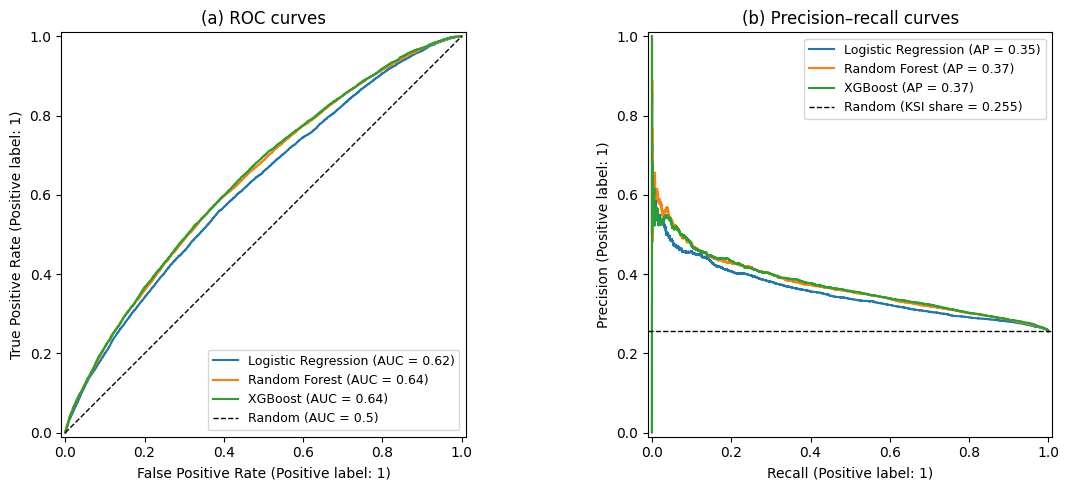

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for name in ["Logistic Regression", "Random Forest", "XGBoost"]:
    RocCurveDisplay.from_predictions(y_test, probs[name], name=name, ax=axes[0])
    PrecisionRecallDisplay.from_predictions(y_test, probs[name], name=name, ax=axes[1])
axes[0].plot([0, 1], [0, 1], "k--", lw=1, label="Random (AUC = 0.5)")
axes[1].axhline(y_test.mean(), color="k", ls="--", lw=1, label=f"Random (KSI share = {y_test.mean():.3f})")
axes[0].set_title("(a) ROC curves"); axes[1].set_title("(b) Precision–recall curves")
for ax in axes: ax.legend(loc="lower right" if ax is axes[0] else "upper right", fontsize=9)
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "fig5_roc_pr_curves.png"), dpi=300)
plt.show()

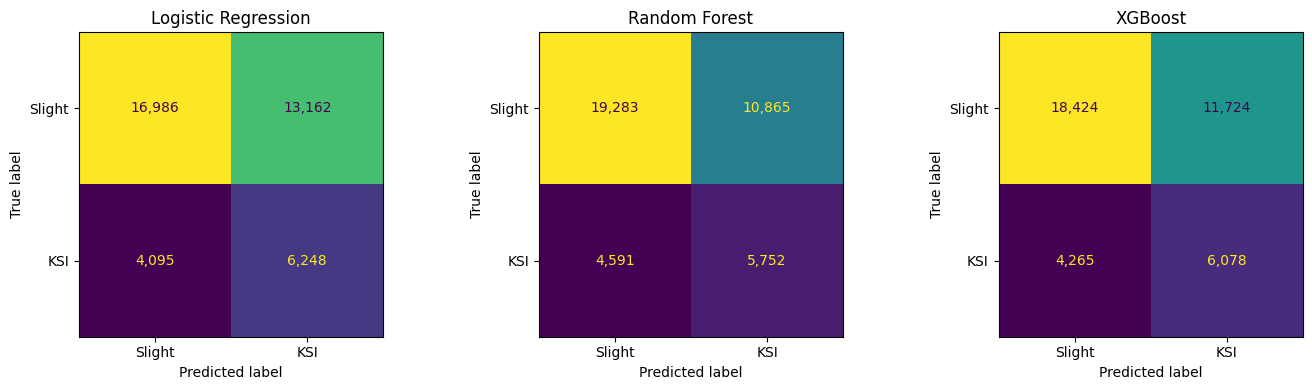

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, name in zip(axes, ["Logistic Regression", "Random Forest", "XGBoost"]):
    ConfusionMatrixDisplay.from_predictions(y_test, (probs[name] >= 0.5).astype(int),
                                            display_labels=["Slight", "KSI"], ax=ax, colorbar=False,
                                            values_format=",")
    ax.set_title(name)
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "fig6_confusion_matrices.png"), dpi=300)
plt.show()

## 6. Additional experiments

### 6a. Class-imbalance handling for XGBoost: none vs class weights vs SMOTE
SMOTE is applied **inside** the training data only (never on the test set), on the one-hot encoded features.

In [10]:
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline

xgb_params = models["XGBoost"].named_steps["clf"].get_params()
def xgb(spw):
    p = dict(xgb_params); p["scale_pos_weight"] = spw
    return XGBClassifier(**p)

variants = {
    "No balancing": Pipeline([("prep", make_prep(False)), ("clf", xgb(1.0))]),
    "Class weights": models["XGBoost"],
    "SMOTE": ImbPipeline([("prep", make_prep(False)), ("smote", SMOTE(random_state=SEED)), ("clf", xgb(1.0))]),
}
imb_rows = []
for name, m in variants.items():
    if name != "Class weights":
        m.fit(X_train, y_train)
    r, _ = evaluate(name, m, X_test, y_test)
    imb_rows.append(r)
imb_df = pd.DataFrame(imb_rows).set_index("Model").round(4)
imb_df.to_csv(os.path.join(DATA_DIR, "m2_imbalance_experiment.csv"))
imb_df

,Accuracy,Precision (KSI),Recall (KSI),F1 (KSI),ROC-AUC,PR-AUC
Model,,,,,,
No balancing,0.7461,0.5568,0.0294,0.0558,0.6412,0.3710
Class weights,0.6051,0.3414,0.5876,0.4319,0.6409,0.3705
SMOTE,0.7446,0.5074,0.0067,0.0132,0.6326,0.3624


### 6b. Decision-threshold tuning
The 0.5 threshold is not necessarily the best. The threshold that maximises F1 is chosen on a **validation split taken from the training set**, then applied once to the test set.

In [11]:
X_tr2, X_val, y_tr2, y_val = train_test_split(X_train, y_train, test_size=0.2, stratify=y_train, random_state=SEED)
from sklearn.base import clone
best_model = clone(models["XGBoost"]).fit(X_tr2, y_tr2)
pv = best_model.predict_proba(X_val)[:, 1]
prec, rec, thr = precision_recall_curve(y_val, pv)
f1s = 2 * prec * rec / (prec + rec + 1e-12)
best_thr = float(thr[np.argmax(f1s[:-1])])
print("Best threshold on validation:", round(best_thr, 3))

thr_rows = [evaluate("XGBoost, threshold 0.5", models["XGBoost"], X_test, y_test, 0.5)[0],
            evaluate(f"XGBoost, threshold {best_thr:.2f}", models["XGBoost"], X_test, y_test, best_thr)[0]]
pd.DataFrame(thr_rows).set_index("Model").round(4)

Best threshold on validation: 0.454


,Accuracy,Precision (KSI),Recall (KSI),F1 (KSI),ROC-AUC,PR-AUC
Model,,,,,,
"XGBoost, threshold 0.5",0.6051,0.3414,0.5876,0.4319,0.6409,0.3705
"XGBoost, threshold 0.45",0.5209,0.3145,0.7420,0.4417,0.6409,0.3705


### 6c. Temporal validation: train on 2024, test on 2025
This checks whether a model trained on one year still works on the next. The change to injury-based reporting (58.8% → 86.5%) means 2025 labels are recorded differently, so some drop is expected.

In [12]:
is25 = X["collision_year"] == 1
m_t = clone(models["XGBoost"]).fit(X[~is25], y[~is25])
temporal = evaluate("XGBoost: train 2024 → test 2025", m_t, X[is25], y[is25])[0]
pd.DataFrame([temporal, results_df.loc["XGBoost"].to_dict() | {"Model": "XGBoost: random 80/20 split"}]
             ).set_index("Model").drop(columns=["Train time (s)"], errors="ignore").round(4)

,Accuracy,Precision (KSI),Recall (KSI),F1 (KSI),ROC-AUC,PR-AUC
Model,,,,,,
XGBoost: train 2024 → test 2025,0.6112,0.3492,0.5575,0.4294,0.6322,0.3723
XGBoost: random 80/20 split,0.6051,0.3414,0.5876,0.4319,0.6409,0.3705


## 7. Which features matter? (permutation importance on the test set)
Permutation importance measures how much ROC-AUC drops when one original column is shuffled. It works on the original columns (not the one-hot dummies), so it is easy to explain in the report. A 30,000-row sample of the test set is used to keep it fast.

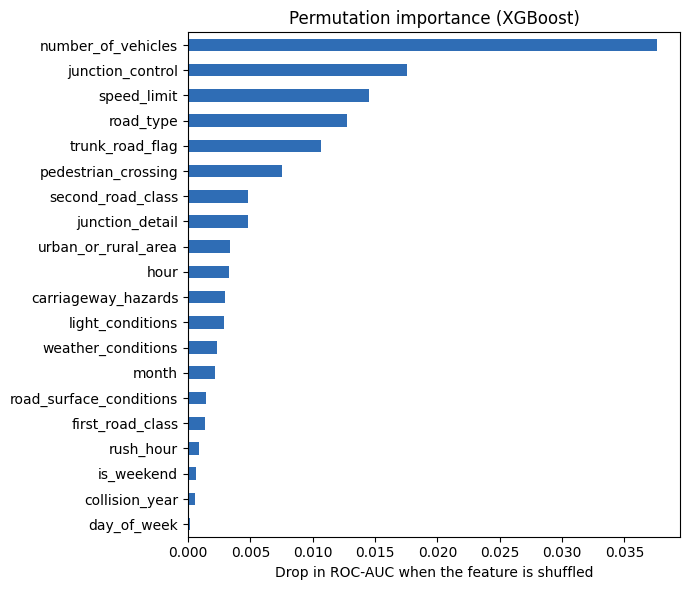

,0
number_of_vehicles,0.0376
junction_control,0.0175
speed_limit,0.0145
road_type,0.0128
trunk_road_flag,0.0106
pedestrian_crossing,0.0076
second_road_class,0.0048
junction_detail,0.0048
urban_or_rural_area,0.0034
hour,0.0033


In [13]:
sample = X_test.sample(30000, random_state=SEED)
pi = permutation_importance(models["XGBoost"], sample, y_test.loc[sample.index], scoring="roc_auc",
                            n_repeats=5, random_state=SEED, n_jobs=1)
imp = pd.Series(pi.importances_mean, index=FEATURES).sort_values()
imp.to_csv(os.path.join(DATA_DIR, "m2_feature_importance.csv"))

fig, ax = plt.subplots(figsize=(7, 6))
imp.plot.barh(ax=ax, color="#2f6db5")
ax.set_xlabel("Drop in ROC-AUC when the feature is shuffled")
ax.set_title("Permutation importance (XGBoost)")
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "fig7_feature_importance.png"), dpi=300)
plt.show()
imp.sort_values(ascending=False).round(4).head(10)

### Control experiment: adding the recording method (`collision_injury_based`)
This column is **not** a crash characteristic, so it is not in the main model. Adding it shows how much of the "prediction" is really about *how police recorded the injury*.

In [14]:
X_ctrl = X.copy(); X_ctrl["collision_injury_based"] = df["collision_injury_based"].values
Xc_tr, Xc_te = X_ctrl.loc[X_train.index], X_ctrl.loc[X_test.index]
prep_c = ColumnTransformer([("num", "passthrough", NUMERIC + BINARY + ["collision_injury_based"]),
                            ("cat", OneHotEncoder(handle_unknown="ignore", min_frequency=50), CATEGORICAL)])
m_c = Pipeline([("prep", prep_c), ("clf", XGBClassifier(**xgb_params))]).fit(Xc_tr, y_train)
pd.DataFrame([results_df.loc["XGBoost"].to_dict() | {"Model": "XGBoost (main features)"},
              evaluate("XGBoost + recording method", m_c, Xc_te, y_test)[0]]
             ).set_index("Model").drop(columns=["Train time (s)"], errors="ignore").round(4)

,Accuracy,Precision (KSI),Recall (KSI),F1 (KSI),ROC-AUC,PR-AUC
Model,,,,,,
XGBoost (main features),0.6051,0.3414,0.5876,0.4319,0.6409,0.3705
XGBoost + recording method,0.6041,0.3422,0.5962,0.4348,0.6460,0.3748


## 8. Summary for the report
* Fill Table V (model comparison) from `m2_model_results.csv`.
* Figures saved in `figures_m2/`: ROC/PR curves (Fig. 5), confusion matrices (Fig. 6), feature importance (Fig. 7).
* Write the interpretation **in your own words** — what the scores mean, which model is best and why, and the limitations.